# From EELS choice traces to adaptive policy identification

**Methods and results**

The original [`llm_decision_making_spectrum.ipynb`](../../llm_decision_making_spectrum.ipynb) asks where an agent chooses to measure next from a menu of image patches, then visualizes the selected EELS spectrum. This notebook connects those **recorded choices** to the later forecasting, policy-ambiguity, and adaptive-experiment results.

The first result section uses **archived P01/P03 decisions**. The adaptive-identification sections use **locally generated synthetic responses**. No new human or original P01/P03 responses were collected. Despite the original notebook filename, the P01/P03 metadata are human-prefixed; their decision-maker, display, prompts, and information access are unverified.


## 1. What the original notebook contains

- Scan 0 has a **66 × 152 structural image**, an EELS cube with **4,198 energy channels**, and logged menus of **20 recorded 16 × 16 patches**. The figure below shows the scan and actual selected locations.
- Five traces total **800 recorded decisions**: P01 and P03 have 100 each, and logged EI, random, and UCB controls have 200 each. P01/P03 share every ordered menu. All traces map to scan 0 in the verified archive inventory.
- The original notebook is a **loader and visualizer**. It shows the scan, candidate menu, selected spectrum, and location maps. Its patch display uses independent `imshow` autoscaling, which does **not** verify the original decision-maker's rendering.

The figures below recreate those visual questions from the validated canonical records. They are retrospective descriptions, not predictor inputs at the current step.


In [ ]:
from pathlib import Path
import json
import pandas as pd

# Works when the notebook is opened from its own folder, eels_study/, or repo root.
def results_dir():
    for base in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        for candidate in (
            base / "adaptive_policy_identification_results",
            base / "eels_study" / "adaptive_policy_identification_results",
        ):
            if (candidate / "EXECUTION_SUMMARY.json").exists():
                return candidate.resolve()
    raise FileNotFoundError("Cannot find eels_study/adaptive_policy_identification_results")

R = results_dir()
STUDY = R.parent
NF = STUDY / "adaptive_policy_identification" / "notebook_figures"
summary = json.loads((R / "EXECUTION_SUMMARY.json").read_text())
print("Saved results:", R)
print("Scientific episodes:", summary["scientific_episodes"])
print("Synthetic choices counted across executions:", summary["synthetic_choices_in_scientific_phases"])
print("Distinct computational response paths:", summary["observation_path_audit"]["distinct_response_paths"])
print("New human/original-participant responses:", summary["human_responses_collected"], "/", summary["original_participant_responses_collected"])


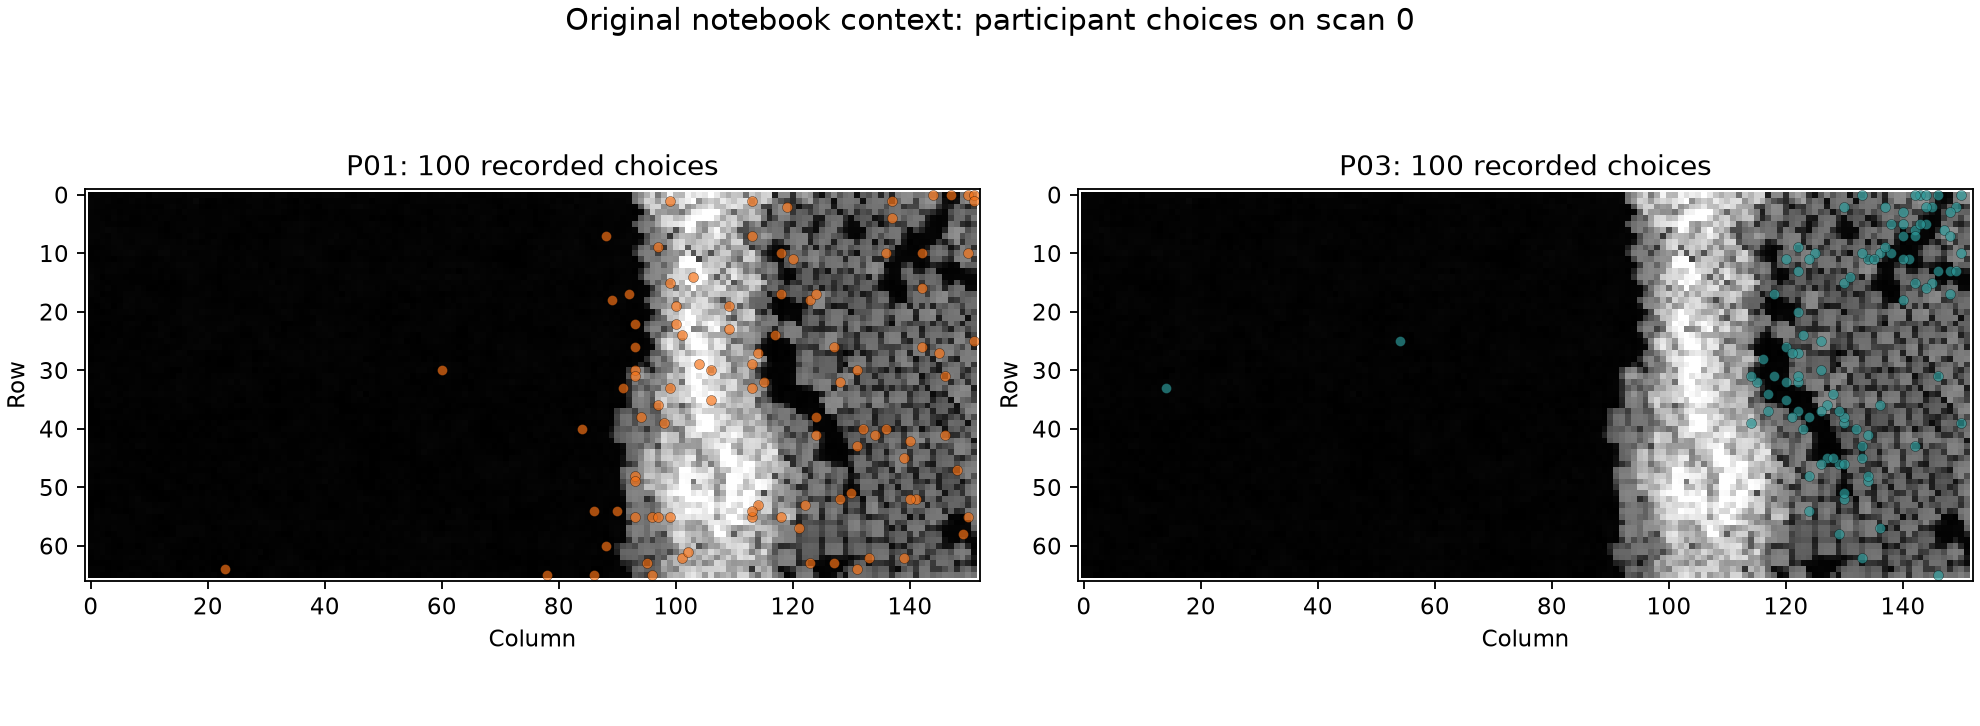

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "original_scan_choices.png")))


P01 and P03 both visit the right-hand structural region, but a map alone does not control for which candidates were offered. They chose the **same slot on 13/100 shared menus**. The saved study also compares each selection with alternatives in its own menu.

The next panel shows one actual P03 decision and the spectrum revealed at the chosen location. Each thumbnail is independently autoscaled **for this visualization only**; the source display is unknown. The spectrum is an outcome, not a feature available before that decision.


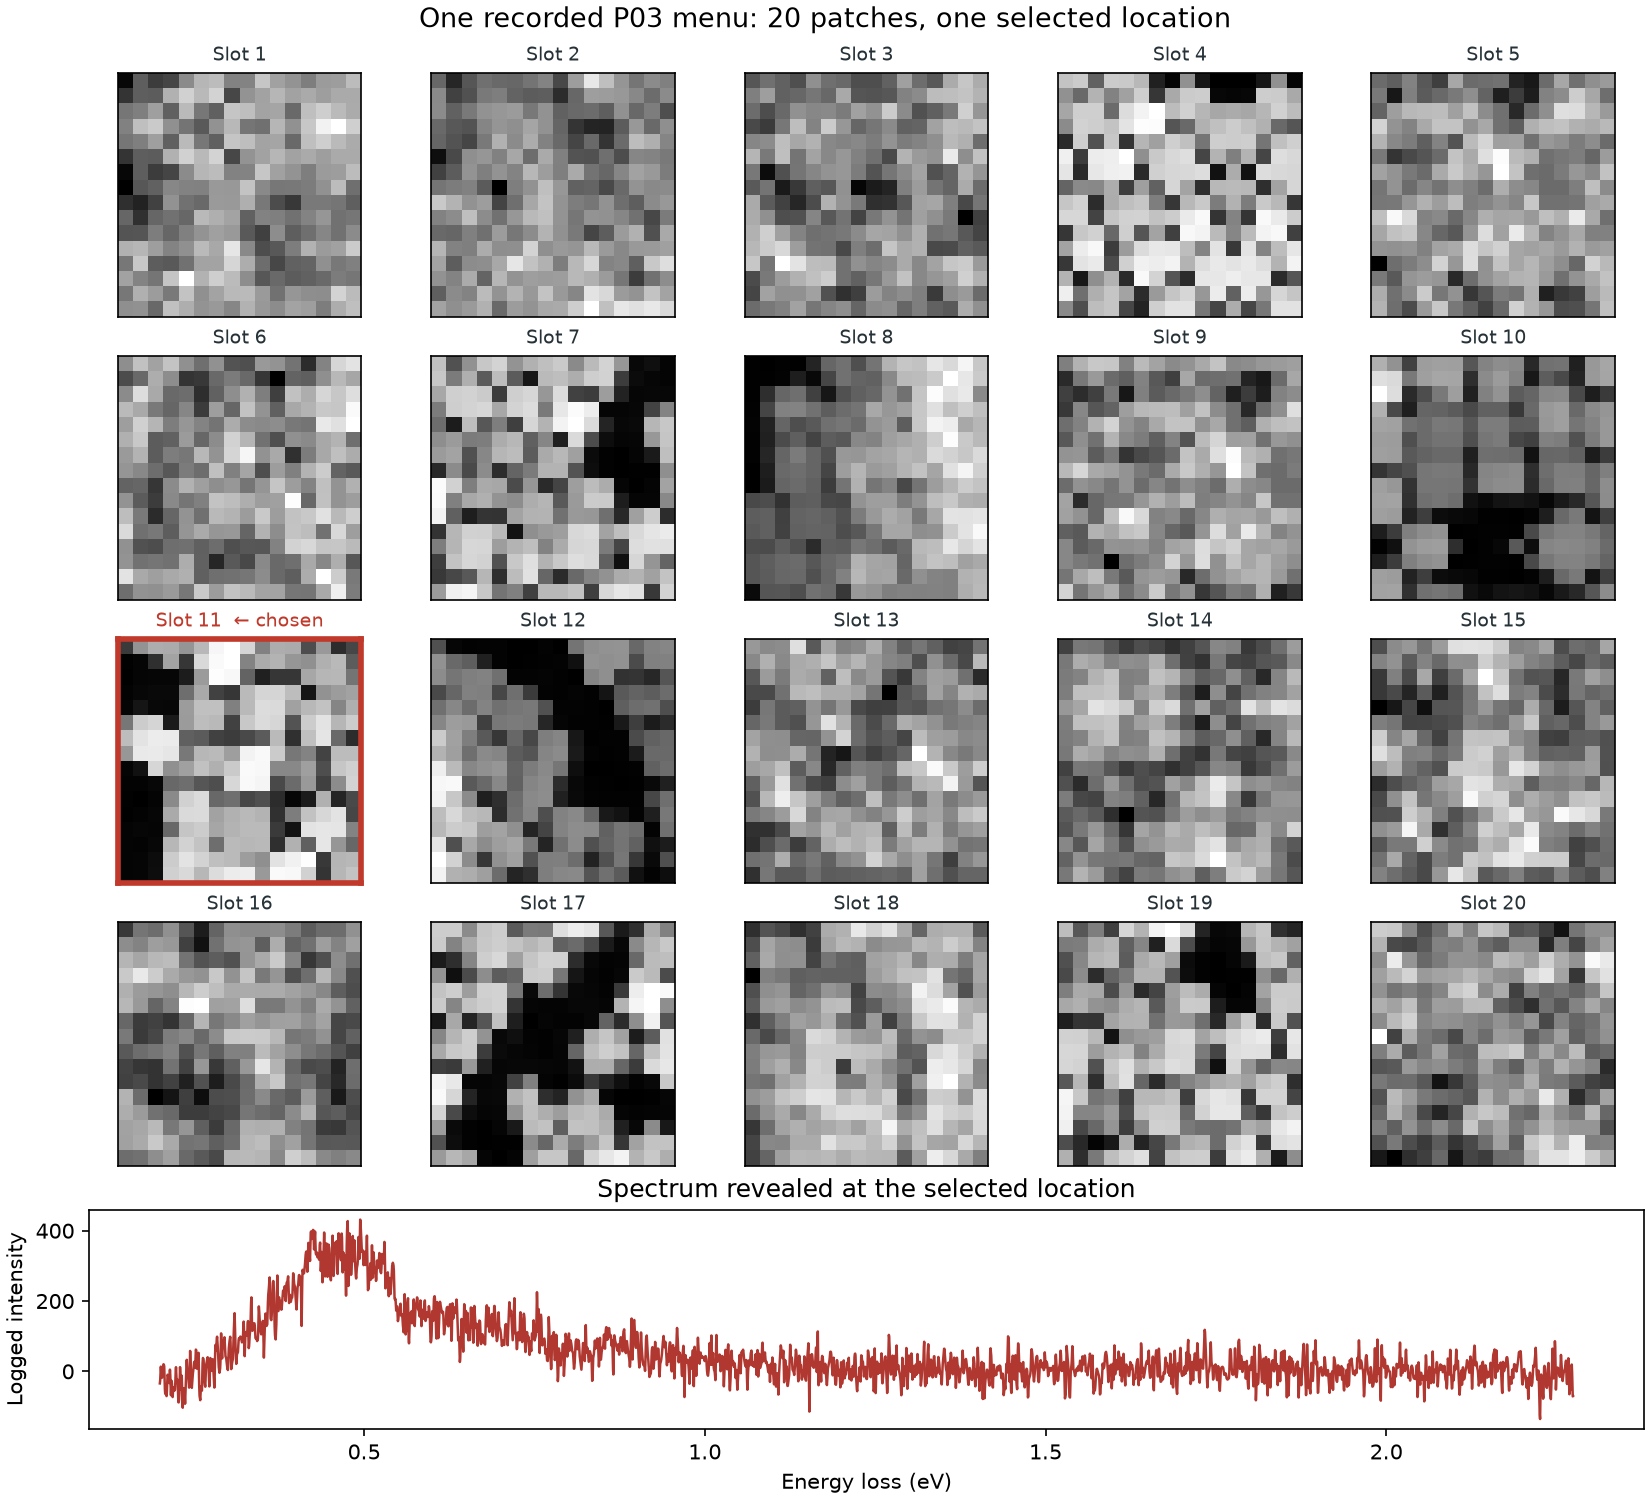

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "original_menu_and_spectrum.png")))


## 2. Forecasting choices already in the archive

The first offline study predicts each participant's next selected **menu position** from that participant's actual earlier choices. It tunes on decisions 1–60 and scores decisions 61–100 **before** revealing each selected outcome, then updates from permitted history. Each 20-way menu is one labeled observation. Current selected spectra and the full cube never enter the primary forecast.

**Top-choice accuracy** is the percentage of decisions for which the model's favorite patch was the one selected. With 20 options, random guessing would average **5%**. The original **M4** image-and-location model correctly predicted **17.5% of P01 choices (7/40)** and **57.5% of P03 choices (23/40)**. Adding visit history and past measured spectra in **M6** gave **20.0% for P01 (8/40)** and **47.5% for P03 (19/40)**. The direct M4-plus-spectra follow-up gave **17.5% / 50.0%**. Even privileged measured-map summaries did not improve the tested heads. These exploratory results do not identify spectral feedback as the decision mechanism or prove it irrelevant; the same suffix has been inspected repeatedly.

Across the later exploratory model search, the **highest observed top-choice accuracies** on these same 40 decisions were **25.0% for P01 (10/40; kernel run a004, tied by other recipes)** and **67.5% for P03 (27/40; shared-encoder run a005)**. These winners were identified *after comparing many models on the same suffix*, so their percentages are descriptive best cases, not independently validated future accuracy. The P01 result is only three additional correct choices over M4. For context, M4's **top-three accuracy** was **47.5% for P01** and **92.5% for P03**.


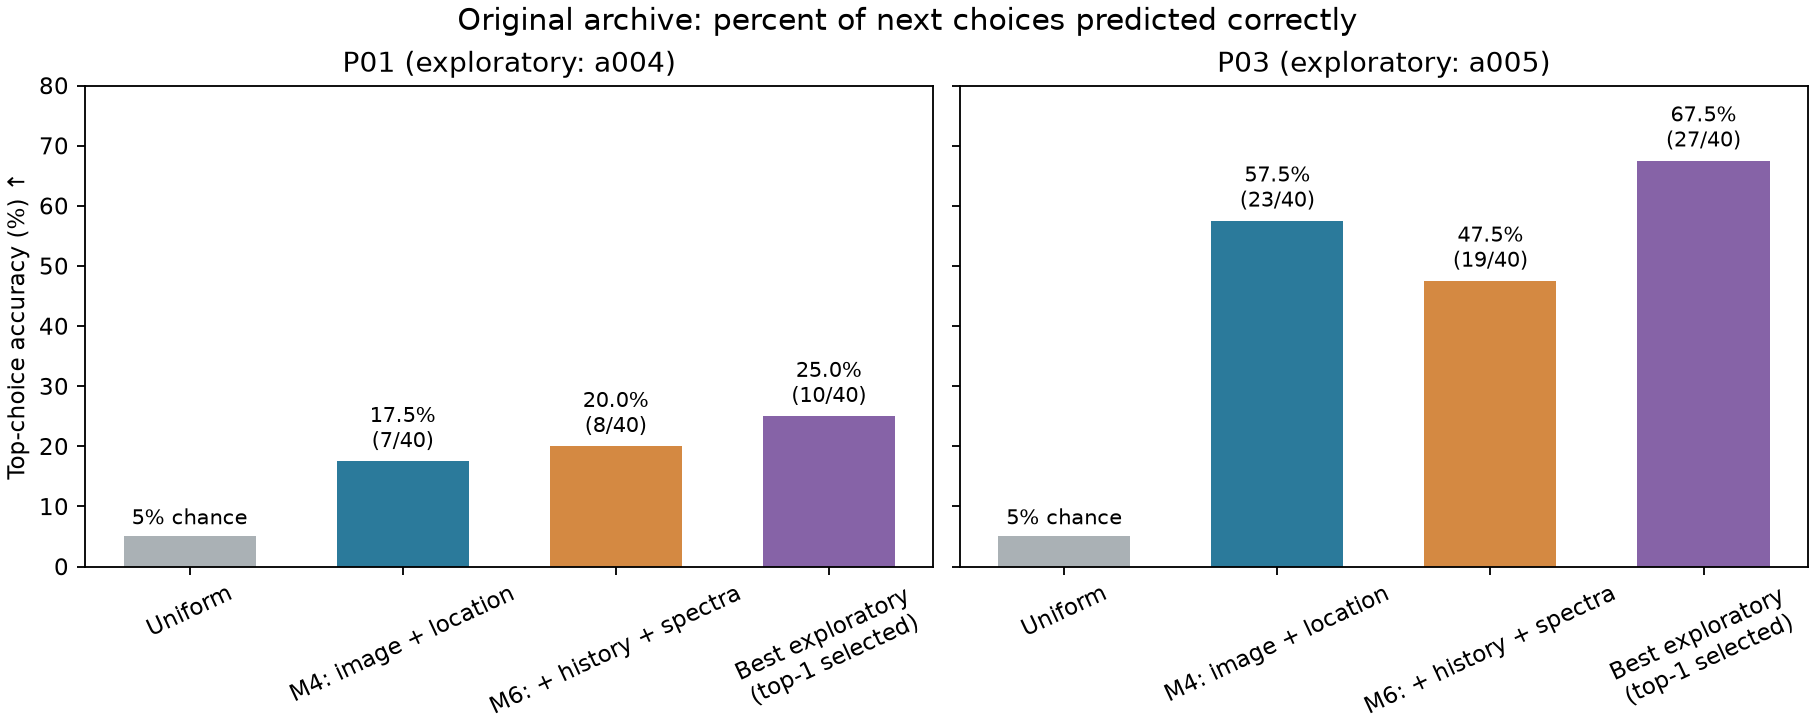

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "archive_choice_forecasts.png")))


### Why the study moved beyond another predictor leaderboard

Later choice-trained visual and strategy models fit the same recorded menus similarly without identifying one stable visual objective. For example, P03's frozen-prefix **M4** and a state-mixture policy gave almost identical probability scores on the archived choices, yet favored **different slots** (16 versus 6, zero-based) on a new registered 20-patch probe. That menu is a **proposed experiment**; P03 has not answered it. On one scan, image appearance and position can also be confounded exactly by a flexible coordinate lookup.

This motivates the next question: *which new menus, repeated choices, or independent images would separate the plausible explanations?*


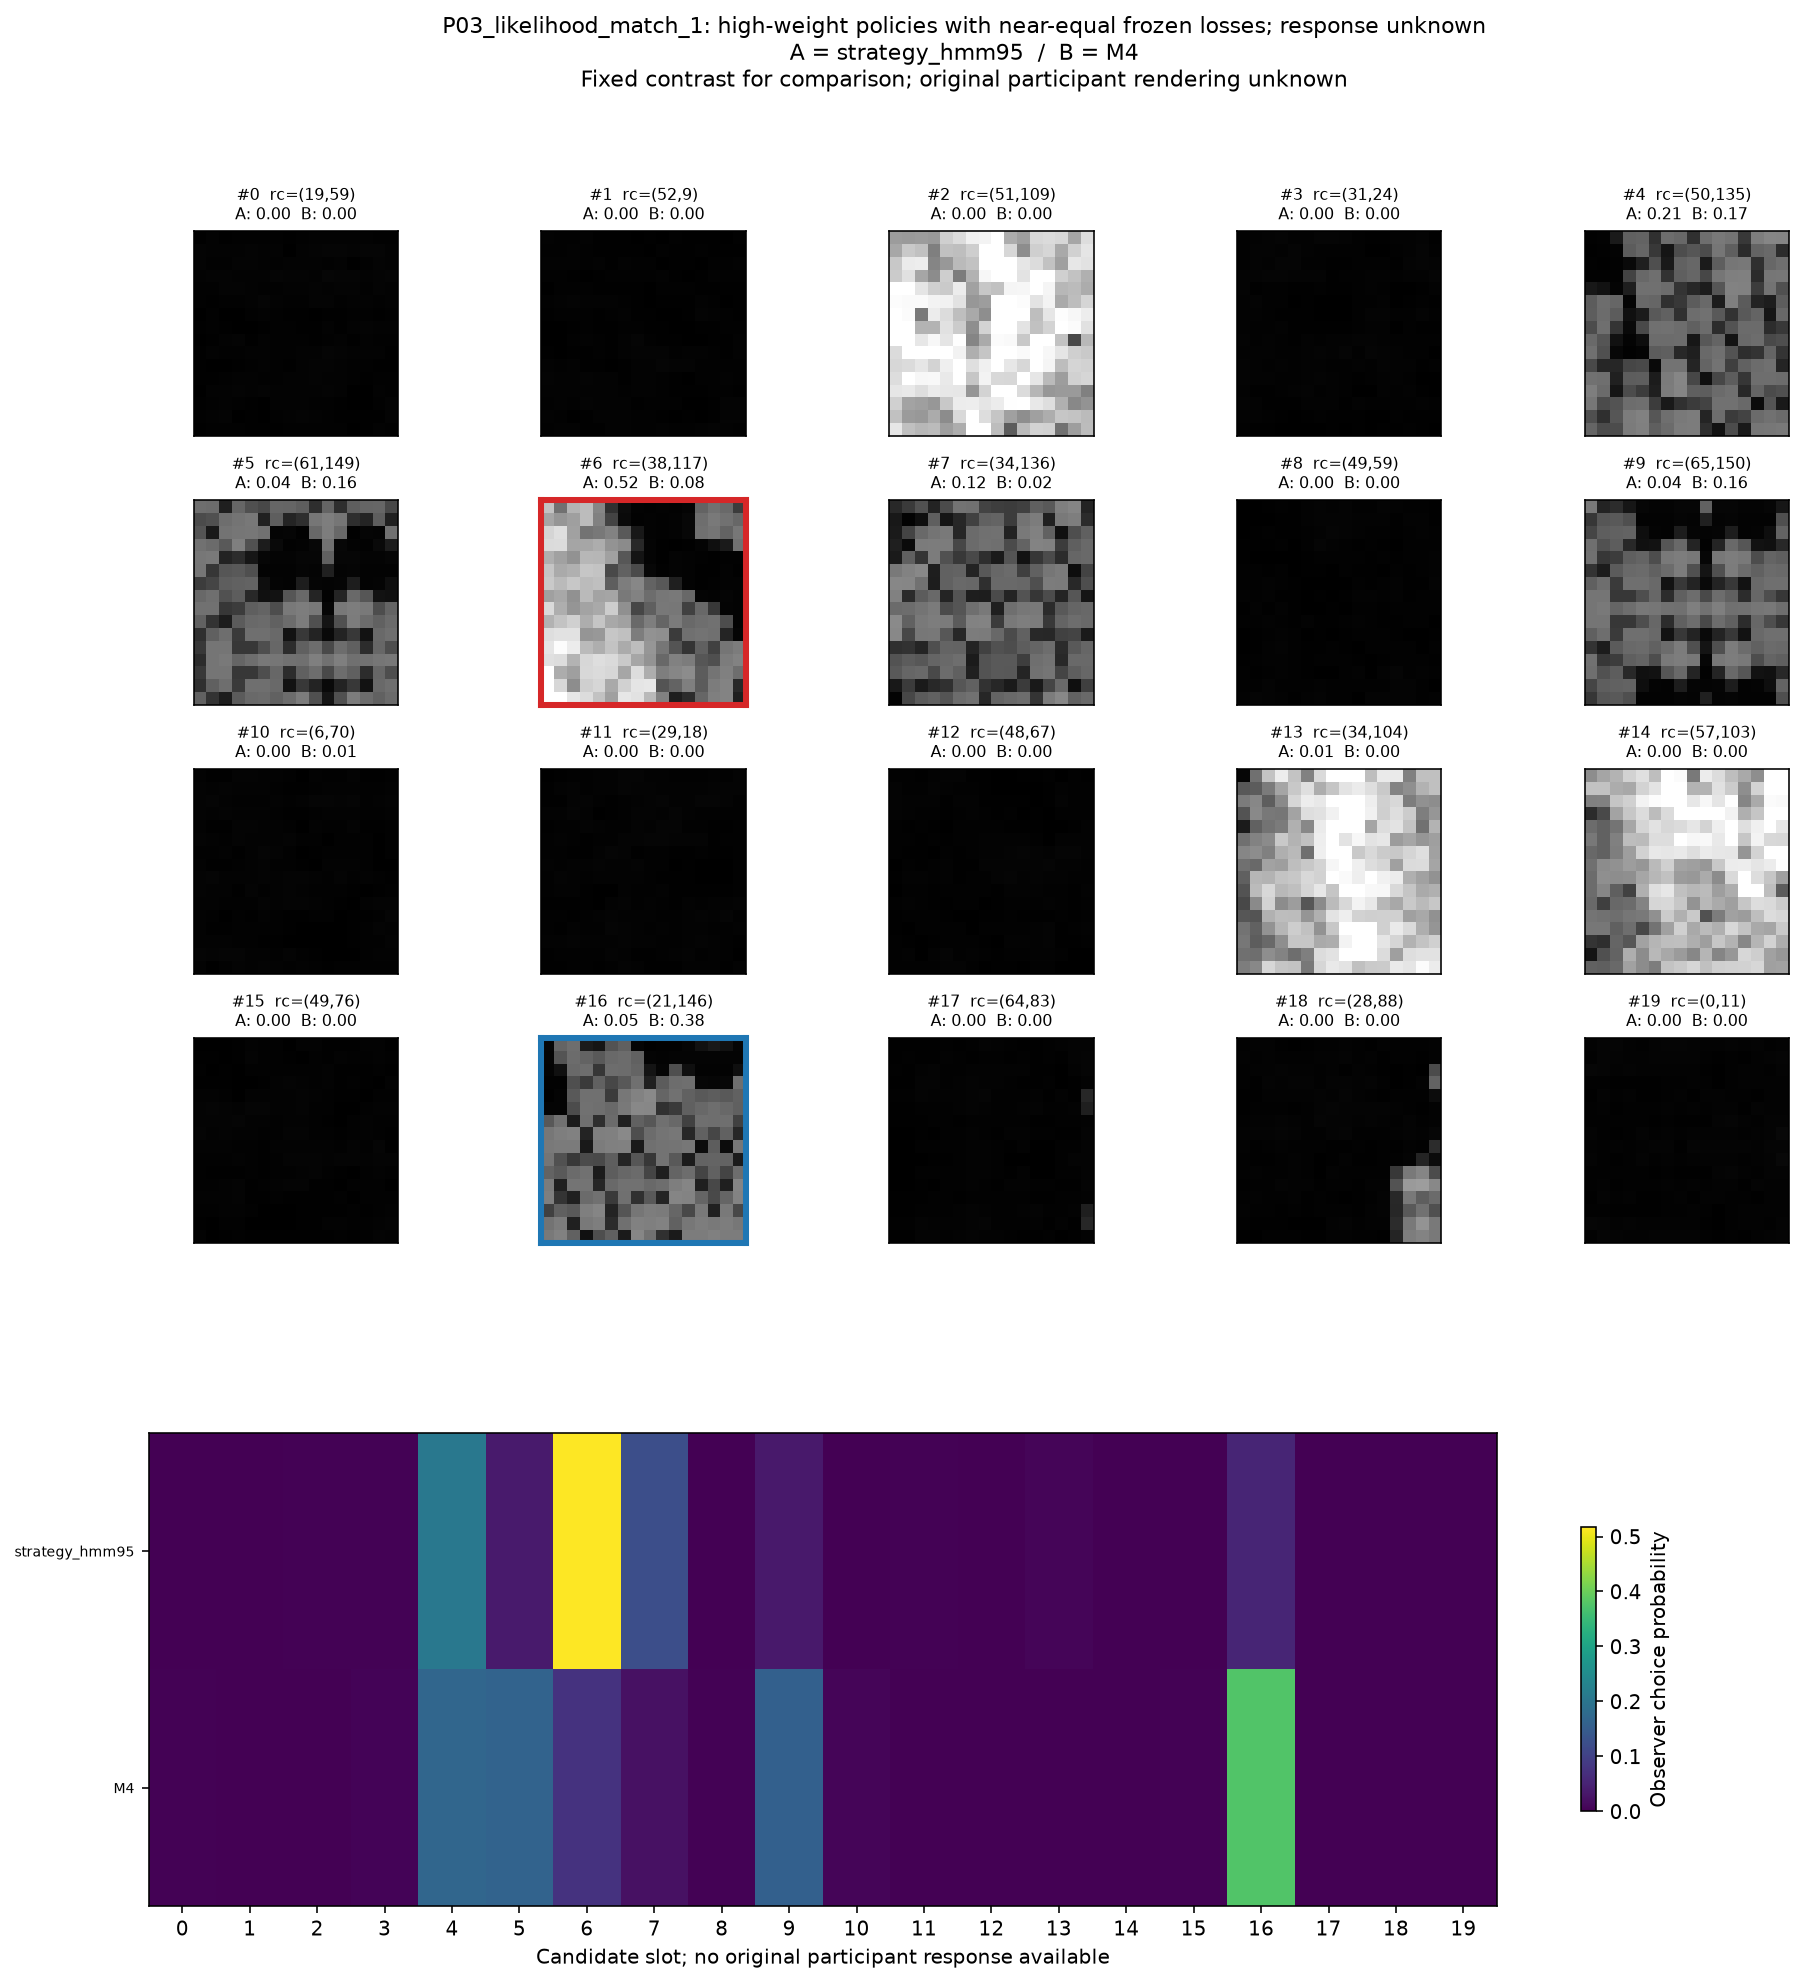

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(STUDY / "counterfactual_policy_discovery_results" / "probe_galleries" / "P03_likelihood_match_1.png")))


## 3. Adaptive methods and prospective instrument

Earlier work recovered **130 callable archived participant-policy combinations** and retained 24 alternatives per participant. The local prospective system uses a **78-policy portfolio** (48 archived fits, 29 portable hypotheses, one background). Archived histories and posterior weights are not transferred to a new person. The separate synthetic benchmark uses a **30-policy portable bank**, 128 proposed menus, and known local agents.

**Experiment loop:** choose menu → compute and save policy forecasts → display all 20 candidates → record answer or abstention → update evidence → select the next menu. Replay verifies the saved order, image hashes, probabilities, and updates.

For each proposed menu \(C\), policy \(m\) predicts a 20-way distribution \(p_m(a\mid C,H_t)\), using only permitted history \(H_t\). The acquisition engine compares **random**, **fixed**, winner disagreement, **expected information gain**, robust information gain, comparison-graph bridging, and an adaptive hybrid. Information gain is

\[
H\!\left(\sum_m w_m p_m
ight)-\sum_m w_m H(p_m).
\]

Responses update log evidence from the probability each policy assigned **before** the choice. Robust updates temper likelihoods, mix in a broad response component, and share a little weight across models. A separate sequential challenger and predictive diagnostics watch for model misspecification. Intentional identical-menu and reordered repeats test consistency and display-slot effects. For new participants, policy histories start empty.

The human application is a local PySide6 desktop interface with consent, mouse/keyboard selection, abstention, breaks, save/resume, and pseudonymous IDs. Every transaction records canonical and displayed candidate IDs, rendering settings, image hashes, pre-response forecasts, timestamps, and response source. It uses no HTTP server, network service, or model API.


## 4. Synthetic evaluation design

The primary benchmark compares seven menu-selection strategies across **8 represented** and **4 out-of-ensemble** synthetic generators, with eight seeds and 60 responses per episode: **672 episodes, 40,320 synthetic responses**. Follow-ups vary inference updates, missing mechanisms, repetition, temporal strategies, and signed visual representations.

Across all reported phases: **1,568 executions and 99,200 counted synthetic choices**. Some follow-ups replay or recompute the same responses. A content audit found **1,282 distinct computational paths** (80,120 choices); these still share images and seeds and are not independent human sessions. The previously inspected archive was used to design the instrument, not as a new prospective test set.

**Measures:** for synthetic sessions with a known mechanism, the percent where the system chose its correct policy family and the percent where it assigned that family at least 80% of its model weight. The latter is a confidence threshold **within the supplied model set**, not an 80% chance of knowing a person's mind. We also report how often the system flagged a deliberately missing mechanism. Crossing times use only sessions that crossed the threshold, so they are **not** guaranteed response budgets.


In [ ]:
bench = pd.read_csv(R / "benchmark" / "summary.csv")
known = bench.loc[bench["known"].eq(True)].copy().sort_values("identified_by_end", ascending=False)
known["correct family (%)"] = (known["correct_family"] * 100).round(1)
known["≥80% model support (%)"] = (known["identified_by_end"] * 100).round(1)
print(known[["strategy", "correct family (%)", "≥80% model support (%)", "median_first_correct80pct_among_reached"]].to_string(index=False))


### Main benchmark finding

Among synthetic agents whose mechanism was in the bank, **information gain and robust information gain identified the correct family with strong model support in 84.4% of sessions**, versus **81.2% with random menus**. Median first crossing **among successful sessions** was 9, 11, and 17 responses, respectively. Robust information gain had the highest end family-classification accuracy (**93.8%**), but no design dominated every agent. These are small, correlated synthetic samples, not independent people.

| Menu design | Correct family (%) | Strong support for correct family (%) | Median first crossing among successes |
|:--|--:|--:|--:|
| Information gain | 89.1 | 84.4 | 9 |
| Robust information gain | 93.8 | 84.4 | 11 |
| Random | 90.6 | 81.2 | 17 |
| Adaptive hybrid | 92.2 | 79.7 | 11 |
| Graph bridge | 89.1 | 78.1 | 19 |
| Greedy disagreement | 92.2 | 73.4 | 13 |
| Fixed | 81.2 | 71.9 | 16.5 |


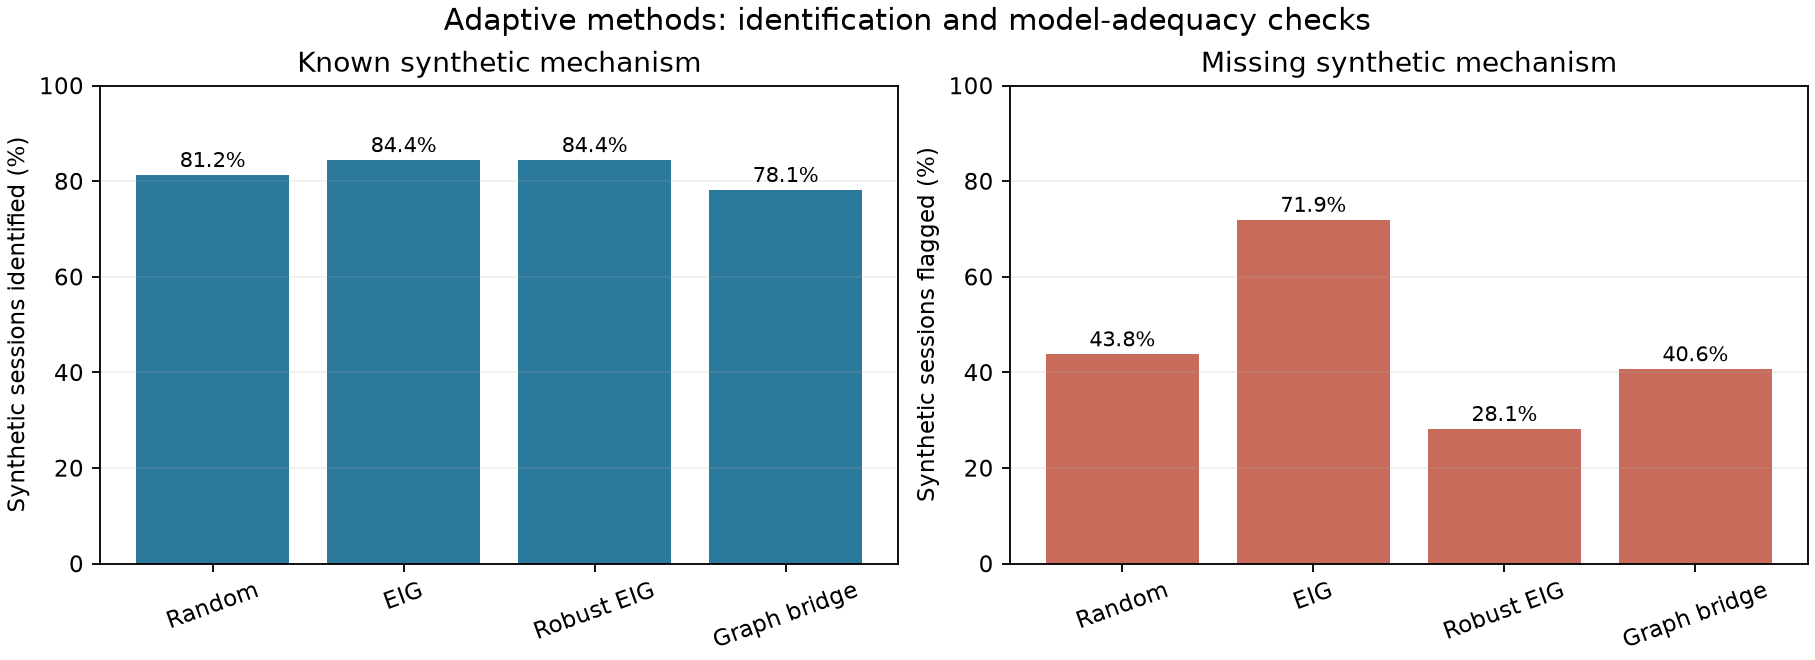

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "adaptive_results_summary.png")))


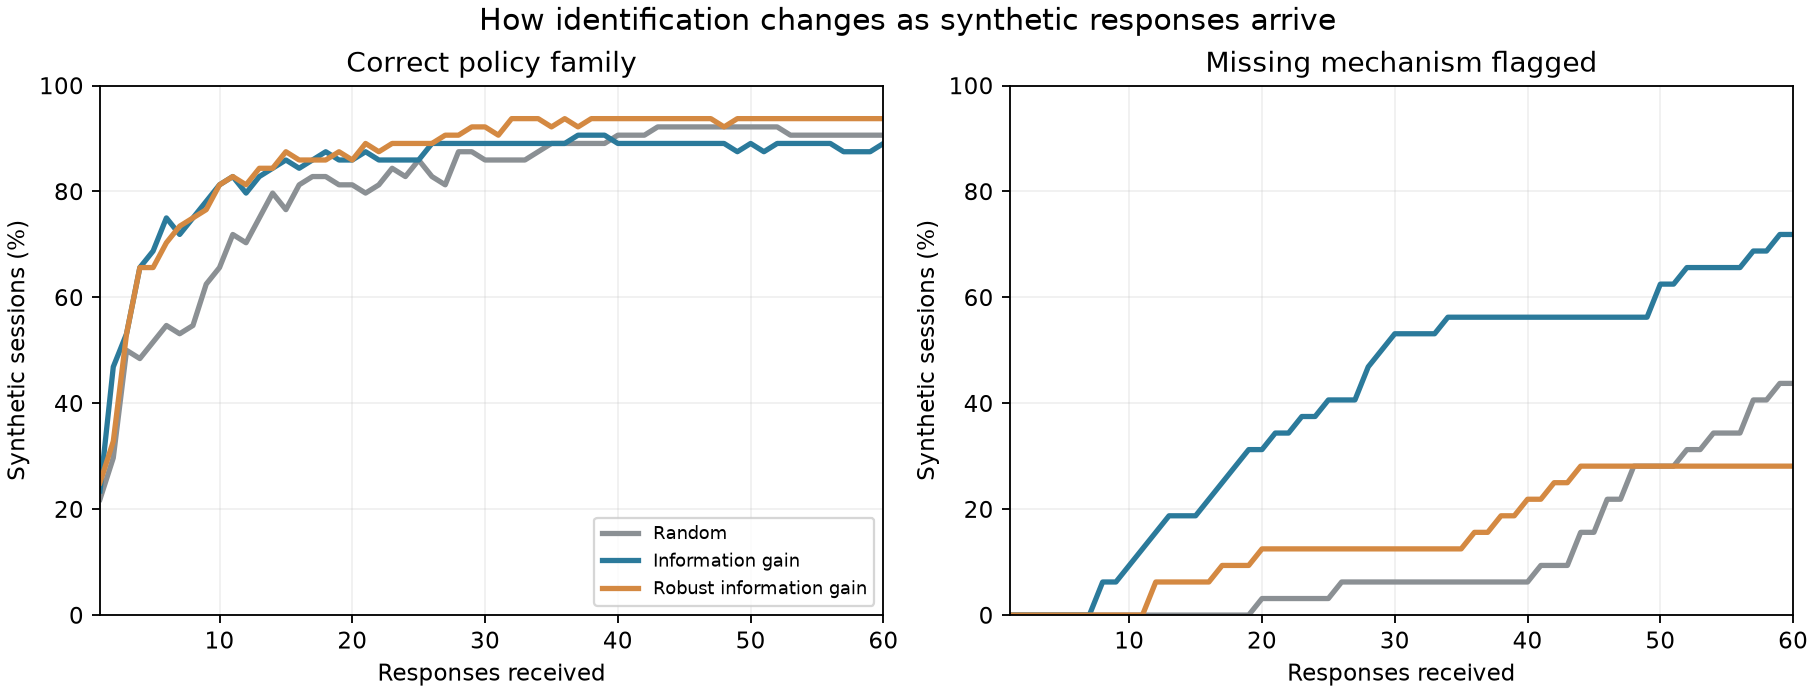

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "adaptive_learning_percent.png")))


## 5. Detecting missing mechanisms

The benchmark included generators absent from the bank. The composite sequential alarm flagged **71.9%** of missing-mechanism sessions under information-gain menus, versus **43.8%** under random menus. It flagged **0%** of the 448 benchmark sessions whose mechanisms were included. This shows useful detection in these tests, with clear blind spots; it does not establish universal power or calibration.

In an exploratory checker replay, adding a predictable switching challenger raised alarm frequency for the missing visual/spatial mixture from **25.0%** to **70.8%**. Other missing generators did not all improve. A coarse state model explained deterministic switching reasonably well (highest family in 24/24 targeted synthetic sessions), while the exact transition schedule remained unidentified. Strong model support is therefore conditional on the available explanations, not proof of a true internal mechanism.


In [ ]:
monitor = pd.read_csv(R / "monitoring_comparison.csv")
mixture = monitor.loc[monitor["agent"].eq("open_mixture"), ["monitor", "runs", "alarm_rate"]].copy()
mixture["sessions flagged (%)"] = (mixture["alarm_rate"] * 100).round(1)
print(mixture[["monitor", "sessions flagged (%)"]].to_string(index=False))


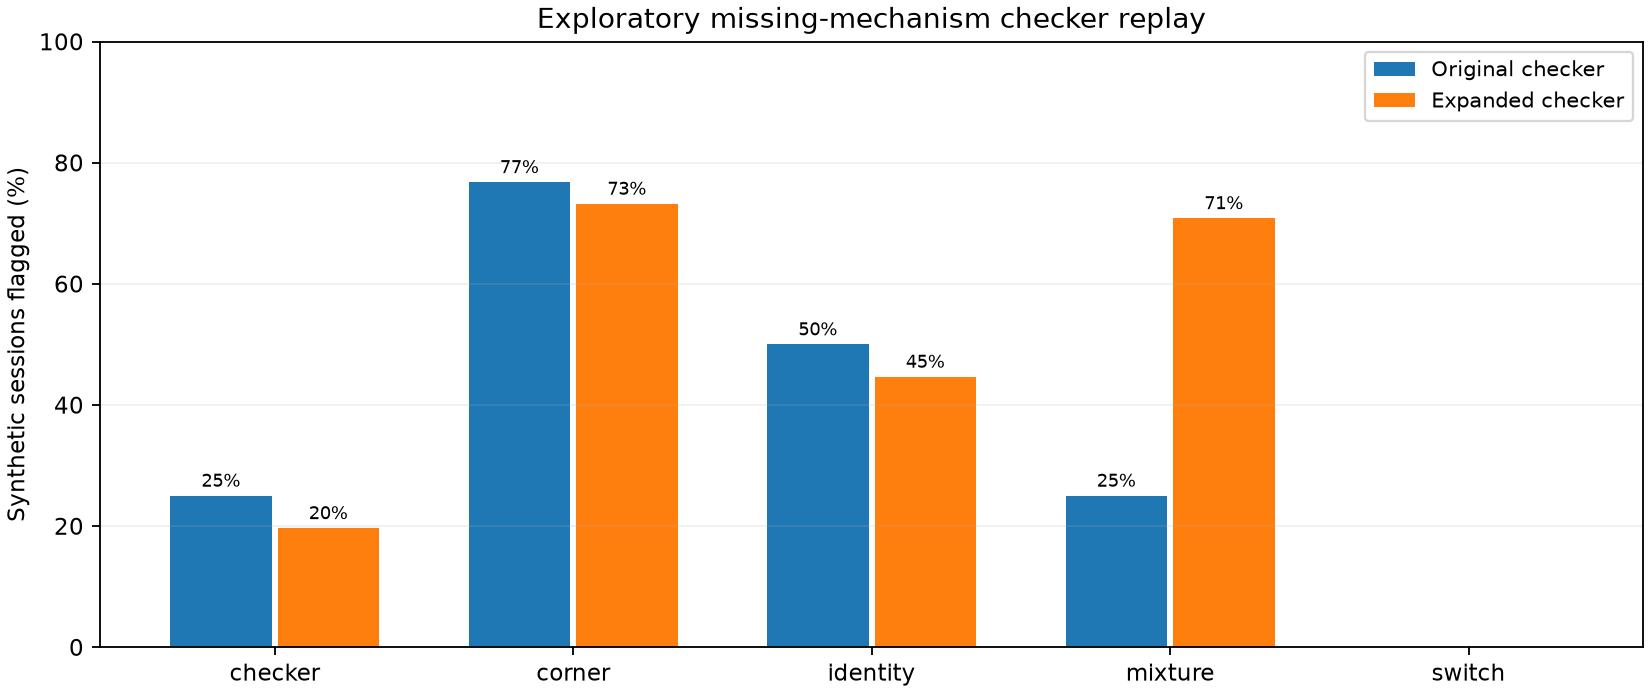

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "misspecification_percent.png")))


**Evidence boundary.** The checker was revised after examining early failures, and its replay is exploratory. A future fixed checker recipe is required for its stated sequential error control. Failure to alarm never certifies that a policy is correct.


## 6. What visual mechanisms are identifiable?

An instructive failure came from the original global bright-ridge and dark-valley summaries: the two policies favored the **same option on 99.2%** of proposed menus. Their names suggested opposite polarity, but the implemented global summaries were effectively the same signal.

A separately versioned *center-weighted signed* representation retained polarity: its bright and dark policies favored **different patches on 100%** of the tested menus. On controlled synthetic agents, the localized bright/dark label was identified in **100% of sessions (48/48)**; the original global labels were identified in **0% (0/48)**. This establishes that the representation made a *synthetic* question answerable. It says nothing yet about the visual preferences of P01 or P03.


In [ ]:
alias = json.loads((R / "representation_equivalence.json").read_text())
print("Original global policies chose the same winner in", f'{100 * alias["global_policy_pair"]["same_winner_fraction"]:.1f}%', "of menus")
print("Localized signed policies chose the same winner in", f'{100 * alias["centered_policy_pair"]["same_winner_fraction"]:.1f}%', "of menus")


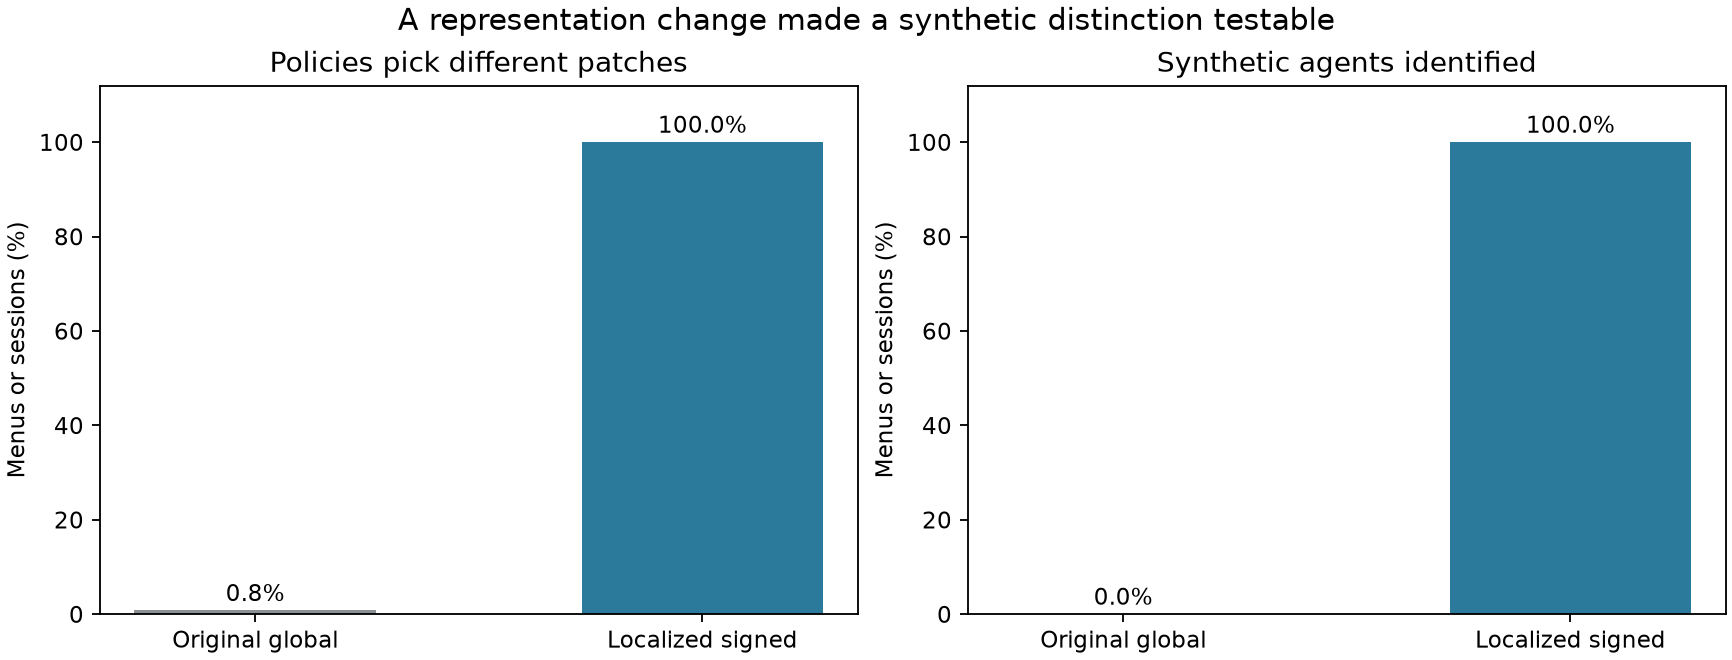

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NF / "representation_percent.png")))


## 7. Bridging comparisons and crossing appearance with location

The original 100 participant menus form **100 disconnected item-comparison components**. Six proposed bridge menus can connect those design strata in a hypothetical continuation. Connectivity alone gives weak precision: under the stated unit-ridge, uniform-choice *expected-information calculation*, the offset covariance trace falls from **99** to **93.68** after six planned responses and **64.49** after 60. Those values are calculations, not observed behavior. A new person starts with no inherited comparison edges.

On one fixed scan, a flexible coordinate lookup can mimic an image-based utility. The platform therefore loads multiple scan arrays with provenance, crop registration, and rendering settings; procedural fields validate the workflow but are not independent measured scans. Crossed appearance/location comparisons on an independently acquired scan are needed to test *transferable* visual versus spatial hypotheses. An unrestricted scan-specific lookup remains possible.


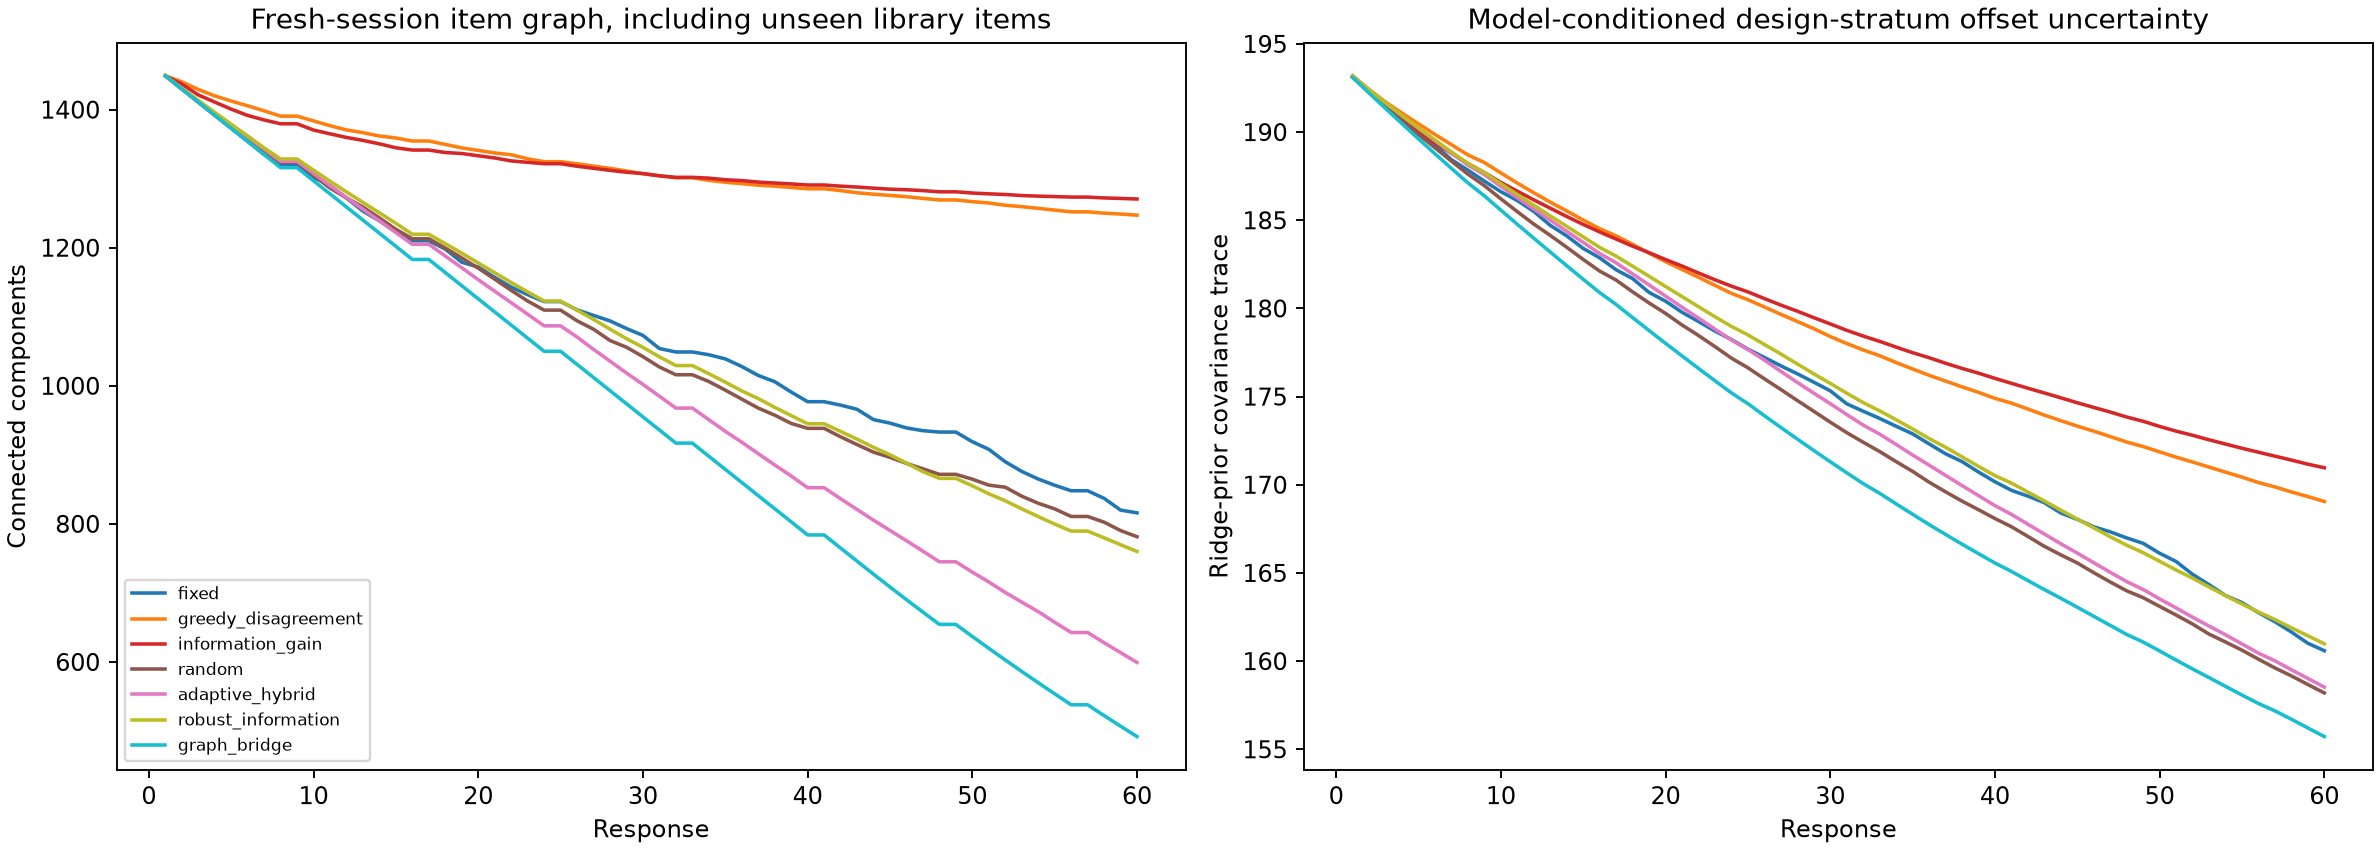

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(R / "figures" / "comparison_graph_connectivity.png")))


## 8. Proposed experiment and research use

**Highest-value next observation:** ask the **same documented decision-maker** to choose from matched-contrast menus on an independently acquired scan where familiar image structures occur at different locations. Use one fixed rendering, familiar-scan anchor menus, three counterbalanced displayed orders, and planned repeats. An initial block of roughly eight menus × three orders (24 responses) is a practical start, **not** an assured identification sample size. Follow with adaptive menus chosen from the updated evidence. If the original participants cannot be verified or recontacted, recruit a new pseudonymous participant and start a new study.

The next panel is a **proposed menu with policy forecasts**, not an observed participant response.



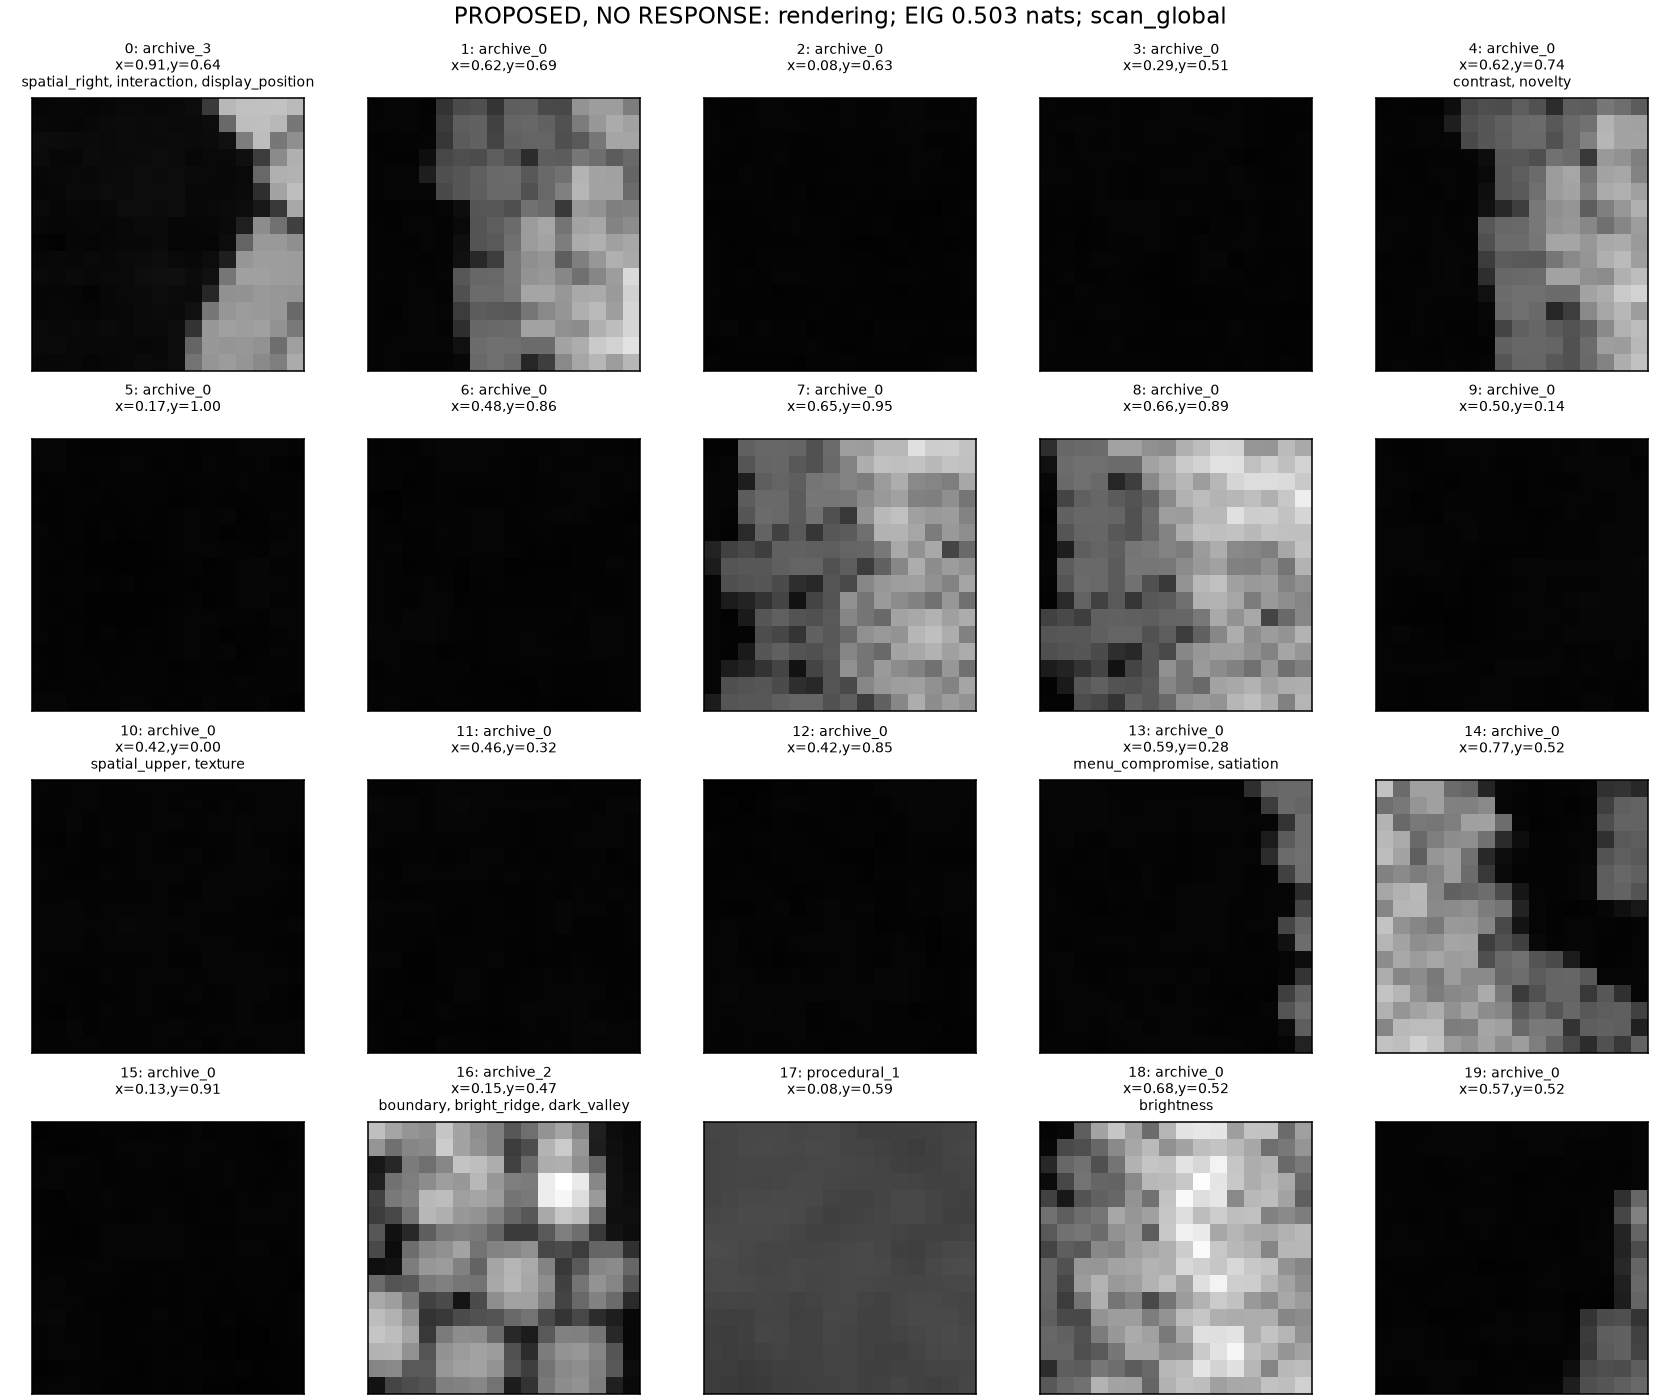

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(R / "figures" / "counterfactual_menu_1.png")))


**Limits.** Two archived participant traces, one overlapping scan, unknown original displays, and no new original responses leave P01/P03 mechanisms unresolved. Identifying a known synthetic generator demonstrates the instrument's behavior under that model bank; it is not evidence of original-participant attention, reward, or causality.

